<style>
@page {
    size: A4;
    margin: 6mm 6mm 6mm 6mm;
}

body {
    font-family: "DejaVu Sans", "Arial", sans-serif;
    font-size: 10px;
    line-height: 1.15;
}

.jp-Notebook {
    max-width: 198mm;
    margin: 0 auto;
}

.jp-Cell {
    page-break-inside: avoid;
    break-inside: avoid;
    margin-top: 2px;
    margin-bottom: 2px;
}

h1, h2, h3, p {
    margin-top: 3px;
    margin-bottom: 3px;
}

pre, code {
    white-space: pre-wrap;
    word-break: break-word;
    overflow-wrap: anywhere;
    font-size: 9px;
}

table {
    width: 100%;
    table-layout: fixed;
    word-wrap: break-word;
}

img, svg, canvas {
    max-width: 100%;
    height: auto;
}

.output_area pre {
    white-space: pre-wrap;
    word-break: break-word;
    overflow-wrap: anywhere;
}
</style>

# T13: График мощности критерия

Используем
$$\tilde F \equiv F(138, 999),\quad \gamma = \frac{\sigma^2_{ег}}{\sigma^2_{ев}},$$
$$W(\gamma)=\tilde F\!\left(\frac{\tilde F_{\alpha/2}}{\gamma}\right)+1-\tilde F\!\left(\frac{\tilde F_{1-\alpha/2}}{\gamma}\right).$$

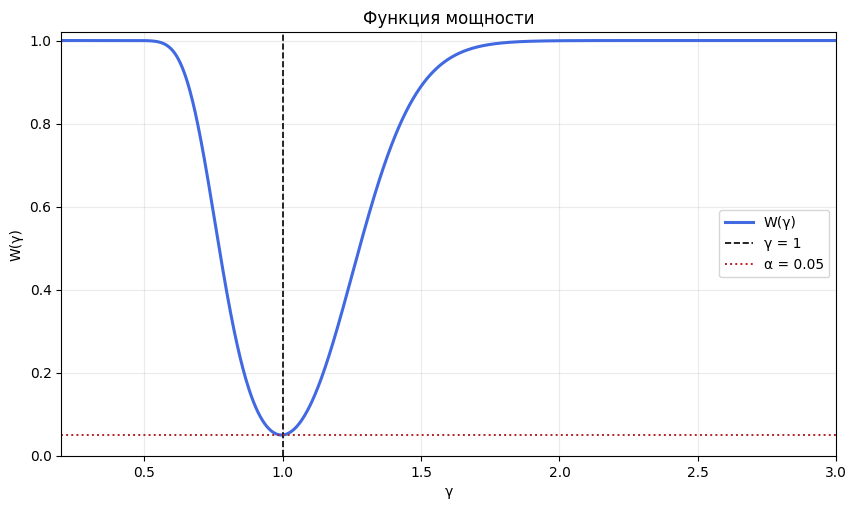

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st

alpha = 0.05
dfn, dfd = 138, 999

F_alpha_2 = st.f.ppf(alpha / 2, dfn, dfd)
F_1_minus_alpha_2 = st.f.ppf(1 - alpha / 2, dfn, dfd)

def W(gamma):
    return st.f.cdf(F_alpha_2 / gamma, dfn, dfd) + 1 - st.f.cdf(F_1_minus_alpha_2 / gamma, dfn, dfd)

gamma_grid = np.linspace(0.2, 3.0, 2000)
power = W(gamma_grid)

plt.figure(figsize=(10, 5.5))
plt.plot(gamma_grid, power, color='royalblue', linewidth=2.2, label='W(γ)')
plt.axvline(1.0, color='black', linestyle='--', linewidth=1.2, label='γ = 1')
plt.axhline(alpha, color='firebrick', linestyle=':', linewidth=1.4, label='α = 0.05')
plt.xlim(gamma_grid[0], gamma_grid[-1])
plt.ylim(0, 1.02)
plt.xlabel('γ')
plt.ylabel('W(γ)')
plt.title('Функция мощности')
plt.grid(alpha=0.25)
plt.legend()
plt.show()